# Metropolis-Hastings


In [1]:
import matplotlib.pyplot as plt

# plt.style.use(
#     "https://github.com/dhaitz/matplotlib-stylesheets/raw/master/pitayasmoothie-dark.mplstyle"
# )

In [2]:
import pandas as pd
import torch
from torch import distributions as dist

## Modelo Poisson-Log Normal

In [62]:
# Parámetro real
lamb = 100.0

# Muestra
n = 100000
x = dist.Poisson(lamb).sample((n,))


def log_posterior(data, lamb, mu=1.0, scale=10.0):

    # Una likelihood para cada cadena
    log_lik = dist.Poisson(lamb[:, None]).log_prob(data).sum(dim=1)

    # Un prior para cada cadena
    log_prior = dist.LogNormal(mu, scale).log_prob(lamb)

    return log_lik + log_prior


# Número de muestras
n_iter = 2000
burn_in = 5000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 3

# Estado inicial de cada cadena
lamb_hat = x.mean()

eta_x = torch.log(lamb_hat * torch.ones(num_chains))

# Almacenamiento
eta = torch.empty((n_iter, num_chains))

# Escala de propuesta
s = 1e-4


for i in range(total_iter):

    # Propuesta para cada cadena
    eta_y = eta_x + s * torch.randn(num_chains)

    # Transformación
    lamb_x = torch.exp(eta_x)
    lamb_y = torch.exp(eta_y)

    # Log posterior
    log_ratio = log_posterior(x, lamb_y) - log_posterior(x, lamb_x) + eta_y - eta_x

    # log(alpha)
    log_alpha = torch.minimum(log_ratio, torch.zeros(num_chains))

    # Uniforme independiente para cada cadena
    log_u = torch.log(torch.rand(num_chains))

    # Aceptación independiente
    accept = log_u < log_alpha

    eta_x = torch.where(accept, eta_y, eta_x)

    # Guardar
    if i >= burn_in:
        eta[i - burn_in] = eta_x


# Pasamos de eta a lambda
lamb_samples = torch.exp(eta)

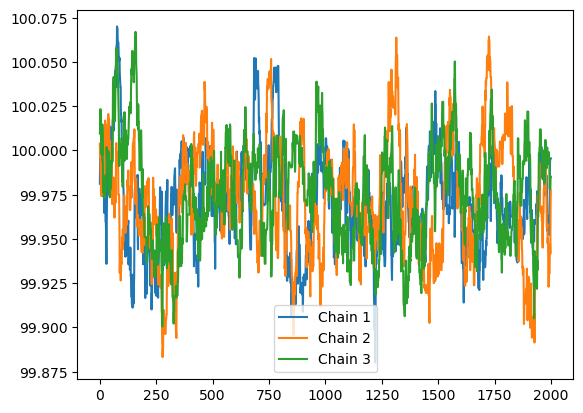

In [63]:
plt.plot(lamb_samples)
plt.legend(["Chain 1", "Chain 2", "Chain 3"])
plt.show()

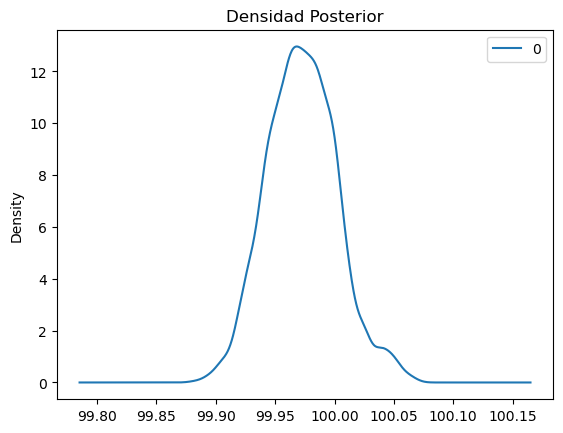

In [64]:
# Densidad Posterior
df_lamb_samples = pd.DataFrame(lamb_samples.flatten())

df_lamb_samples.plot.kde()
plt.title("Densidad Posterior")
plt.show()

In [65]:
# Descripción de la densidad posterior
df_lamb_samples.describe()

,0
count,6000.000000
mean,99.972618
std,0.029578
min,99.880203
25%,99.952003
50%,99.972069
75%,99.992245
max,100.070076


In [66]:
# Intervalo de probabilidad posterior
alpha = 0.05
df_lamb_samples.quantile([alpha / 2, 1 - alpha / 2]).T

,0.025,0.975
0,99.917976,100.038499


## Regresión Logística 

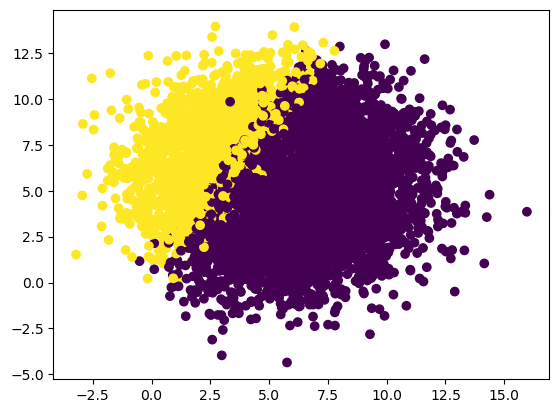

In [89]:
# Parámetros reales

W_real = torch.Tensor([0.2, -2.5, 1.4])

n = 10000
p = 2


X = 5.5 + 2.5 * torch.randn((n, p))
X_desing = torch.column_stack((torch.ones(n), X))

eta = X_desing @ W_real.T

z = torch.sigmoid(eta)

y = torch.bernoulli(z)


plt.scatter(X_desing[:, 1], X_desing[:, 2], c=y)
plt.show()

In [235]:
def log_posterior(X_desing, y, W, mu=0.0, scale=1.0):

    eta = X_desing @ W

    log_lik = dist.Bernoulli(logits=eta).log_prob(y[:, None]).sum(dim=0)

    log_prior = dist.Normal(mu, scale).log_prob(W).sum(dim=0)

    return log_lik + log_prior

In [236]:
# Número de muestras
n_iter = 3000
burn_in = 5000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 3

# Estado inicial de cada cadena
W_x = torch.zeros((p + 1, num_chains))


# Almacenamiento
W = torch.empty((n_iter, p + 1, num_chains))

# Escala de propuesta
s = 1e-2


accept_count = torch.zeros(num_chains)

for i in range(total_iter):

    W_y = W_x + s * torch.randn((p + 1, num_chains))

    log_ratio = (
        log_posterior(X_desing, y, W_y)
        - log_posterior(X_desing, y, W_x)
    )

    log_alpha = torch.minimum(log_ratio, torch.zeros(num_chains))

    log_u = torch.log(torch.rand(num_chains))

    accept = log_u < log_alpha

    accept_count += accept

    W_x = torch.where(accept, W_y, W_x)

    if i >= burn_in:
        W[i - burn_in] = W_x

accept_rate = accept_count / total_iter

print(accept_rate)

tensor([0.5491, 0.5474, 0.5598])


<Axes: ylabel='Density'>

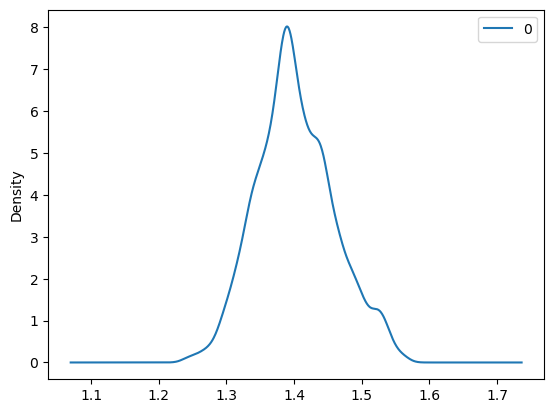

In [239]:
data_W_0 = pd.DataFrame(W[:, 2, :].flatten())
data_W_0.plot.kde()

In [242]:
data_W_0.describe()

,0
count,9000.000000
mean,1.402001
std,0.057446
min,1.236429
25%,1.362973
50%,1.397060
75%,1.439367
max,1.569629


In [216]:
W[:, 0, :]

tensor([[ 4.2050e-04,  5.7122e-05, -4.6552e-04],
        [ 4.3067e-04,  6.3081e-05, -4.7331e-04],
        [ 4.3334e-04,  7.3817e-05, -4.6987e-04],
        ...,
        [-7.9291e-04, -1.7297e-04, -1.1318e-03],
        [-7.9654e-04, -1.7253e-04, -1.1189e-03],
        [-8.0206e-04, -1.7253e-04, -1.1197e-03]])

In [202]:
W.view(3, 15000)

tensor([[ 0.3657,  0.3994,  0.5711,  ..., -2.7149, -2.4722, -2.6136],
        [ 1.5106,  1.3593,  1.4714,  ...,  0.6891,  0.0798,  0.3785],
        [-2.5587, -2.4919, -2.5205,  ...,  1.3646,  1.4149,  1.3557]])